# Part E: fine-tuning BERT

All the weights of BERT are now trained.

1. E1: AraBERT and CAMeLBERT, one model for categories and one for polarity
2. Seeds of the winners
3. E2: one shared encoder with two heads, and the effect of λ
4. E1 pipeline against E2
5. Gain and cost against frozen BERT (Q8)

The starting point of the subject: lr 2e-5, batch 32, 4 epochs, 10% warmup, early stopping on val. Comparisons use seed 42, and only the winners get seeds 43 and 44, which gives 13 trainings. Each saved model takes about 215 MB on Drive, so keep 3 GB free.


**Running this notebook.** Each model has its own cell, and a finished run is saved on Drive. If a cell fails, rerun only that cell. After a lost session, run the notebook again: finished runs reload in seconds. To train one again, pass `retrain=True` in its cell.

## Setup

In [1]:
import os
import sys
from google.colab import drive
drive.mount("/content/drive")

REPO = "AR-aspect-sentiment"

if not os.path.exists(f"/content/{REPO}"):
    !git clone https://github.com/cad0m/{REPO}.git /content/{REPO}
else:
    !git -C /content/{REPO} pull

%cd /content/{REPO}

if f"/content/{REPO}" not in sys.path:
    sys.path.insert(0, f"/content/{REPO}")

!pip install -q arabert emoji gensim sentencepiece tashaphyne

OUTPUT_DIR = f"/content/drive/MyDrive/{REPO}"
os.environ["OUTPUT_DIR"] = OUTPUT_DIR
!mkdir -p {OUTPUT_DIR} && cp -rn results {OUTPUT_DIR}/

Mounted at /content/drive
Cloning into '/content/AR-aspect-sentiment'...
remote: Enumerating objects: 83, done.
remote: Counting objects: 100% (83/83), done.
remote: Compressing objects: 100% (59/59), done.
remote: Total 83 (delta 30), reused 62 (delta 19), pack-reused 0 (from 0)
Receiving objects: 100% (83/83), 4.53 MiB | 16.61 MiB/s, done.
Resolving deltas: 100% (30/30), done.
/content/AR-aspect-sentiment
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from arabert.preprocess import ArabertPreprocessor
from torch import nn
from torch.utils.data import DataLoader
from transformers import (
    AutoModel,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)

from src.aspect_names import aspect_name
from src.data import POLARITIES, category_list, category_matrix, load_test, load_train_val, pair_units, pairs
from src.evaluation import (
    THRESHOLD_GRID,
    accuracy_by_mixed_sentence,
    best_category_thresholds,
    best_global_threshold,
    category_report,
    category_scores,
    compare_threshold_policies,
    pairs_from_matrix,
    pipeline_outcomes,
    pipeline_scores,
    polarity_f1_by_class,
    polarity_scores,
    predict_labels,
)
from src.plots import (
    plot_category_f1,
    plot_f1_by_threshold,
    plot_grouped_bars,
    plot_mixed_accuracy,
    plot_model_comparison,
    plot_pipeline_outcomes,
    plot_polarity_confusion,
    plot_polarity_f1,
    plot_quality_against_cost,
    plot_threshold_policies,
    plot_training_curves,
)
from src.tracking import best_of_each_model, cached_run, latency_ms, log_results, result_row, save_scores
from src.training import DEVICE, collect_outputs, compact_state, fit, set_seed, token_inputs, tokenized_rows

SEED = 42
BERT_NAMES = {
    "arabert": "aubmindlab/bert-base-arabertv02",
    "camelbert": "CAMeL-Lab/bert-base-arabic-camelbert-msa",
}
LEARNING_RATE = 2e-5
BATCH_SIZE = 32
EPOCHS = 4
PATIENCE = 2
MAX_LENGTH = 128
ASPECT_SIZE = 32
sns.set_theme(style="whitegrid", context="notebook")
print("Device:", DEVICE)

Device: cuda


In [3]:
opinions, train, val = load_train_val(SEED)

classes = category_list(opinions)
category_ids = {name: index for index, name in enumerate(classes)}
polarity_ids = {name: index for index, name in enumerate(POLARITIES)}

train_labels = category_matrix(train.categories, classes)
val_labels = category_matrix(val.categories, classes)

val_pairs = pairs(opinions, val)
train_units = pair_units(pairs(opinions, train))
train_units = train_units[~train_units.ambiguous].reset_index(drop=True)
val_units = pair_units(val_pairs)
clear_units = ~val_units.ambiguous.to_numpy(dtype=bool)

tokenizers = {name: AutoTokenizer.from_pretrained(path) for name, path in BERT_NAMES.items()}
PREPARE_TEXT = {"arabert": ArabertPreprocessor(BERT_NAMES["arabert"]).preprocess, "camelbert": lambda text: text}

print(f"{len(train)} train and {len(val)} val sentences, {len(train_units)} and {len(val_units)} pairs")

config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/381 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/825k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.64M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/468 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

4301 train and 481 val sentences, 8060 and 930 pairs


Both losses are weighted. A positive category weighs `sqrt(negatives / positives)`, and each polarity gets the same total weight.

In [4]:
positive_counts = train_labels.sum(axis=0).clip(min=1)
category_loss = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(np.sqrt((len(train) - positive_counts) / positive_counts), dtype=torch.float32, device=DEVICE))

polarity_counts = train_units.polarity.map(polarity_ids).value_counts().sort_index().to_numpy()
polarity_loss = nn.CrossEntropyLoss(weight=torch.tensor(len(train_units) / (len(POLARITIES) * polarity_counts), dtype=torch.float32, device=DEVICE))


def make_loader(rows, backbone, shuffle=False):
    return DataLoader(rows, batch_size=BATCH_SIZE, shuffle=shuffle, collate_fn=DataCollatorWithPadding(tokenizers[backbone]))


def make_optimizer(model, n_batches):
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    total_steps = EPOCHS * n_batches
    return optimizer, get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)


def new_model(backbone, n_outputs):
    return AutoModelForSequenceClassification.from_pretrained(BERT_NAMES[backbone], num_labels=n_outputs).to(DEVICE)

## 1. E1: one model per task

### Categories: 34 sigmoids

In [5]:
def sentence_rows(sentence_table, backbone, labels=None):
    texts = sentence_table.text.map(PREPARE_TEXT[backbone])
    return tokenized_rows(tokenizers[backbone], texts, labels=None if labels is None else labels.astype(float).tolist(), max_length=MAX_LENGTH)


def category_probabilities(model, loader):
    return collect_outputs(loader, lambda batch: model(**token_inputs(batch)).logits).sigmoid().numpy()


def category_result(scores):
    threshold, _ = best_global_threshold(scores, val_labels)
    return category_scores(val_labels, predict_labels(scores, threshold))


def run_e1_category(backbone, seed=SEED, retrain=False):
    val_loader = make_loader(sentence_rows(val, backbone, val_labels), backbone)

    def train_model():
        set_seed(seed)
        model = new_model(backbone, len(classes))
        train_loader = make_loader(sentence_rows(train, backbone, train_labels), backbone, shuffle=True)
        optimizer, scheduler = make_optimizer(model, len(train_loader))
        history = fit(
            model, train_loader,
            lambda model, batch: category_loss(model(**token_inputs(batch)).logits, batch["labels"]),
            lambda model: category_result(category_probabilities(model, val_loader))["micro_f1"],
            optimizer, scheduler, EPOCHS, PATIENCE, mixed_precision=True,
        )
        return {"state": compact_state(model), "scores": category_probabilities(model, val_loader), "history": history}

    run = cached_run(f"e1_category_{backbone}_seed{seed}", train_model, retrain)
    run.pop("state")
    result = category_result(run["scores"])
    fit_time = run["history"][-1]["seconds"]
    log_results([result_row("category", f"E1 fine-tuned {backbone}", "raw", "lr=2e-5, weighted", "global", fit_time, seed=seed, **result)])
    print(f"{backbone}, seed {seed}: micro-F1 {result['micro_f1']:.4f}, macro-F1 {result['macro_f1']:.4f}, {fit_time:.0f}s")
    return {"name": backbone, "seed": seed, "fit_time_s": fit_time, **run, **result}

In [6]:
arabert_category = run_e1_category("arabert")

model.safetensors: reconstructing file:   0%|          |  0.00B /  543MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1/4:   0%|          | 0/135 [00:00<?, ?it/s]

...

epoch 4/4:   0%|          | 0/135 [00:00<?, ?it/s]

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 4: loss 0.3435, val 0.5854, 110s


predicting:   0%|          | 0/16 [00:00<?, ?it/s]

e1_category_arabert_seed42: saved
arabert, seed 42: micro-F1 0.5854, macro-F1 0.2723, 110s


In [7]:
camelbert_category = run_e1_category("camelbert")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  439MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-msa
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSIN

model.safetensors: reconstructing file:   0%|          |  0.00B /  439MB            

...

epoch 4/4:   0%|          | 0/135 [00:00<?, ?it/s]

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 4: loss 0.3437, val 0.5711, 91s


predicting:   0%|          | 0/16 [00:00<?, ?it/s]

e1_category_camelbert_seed42: saved
camelbert, seed 42: micro-F1 0.5711, macro-F1 0.2953, 91s


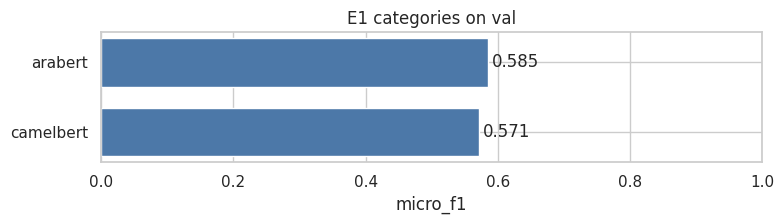

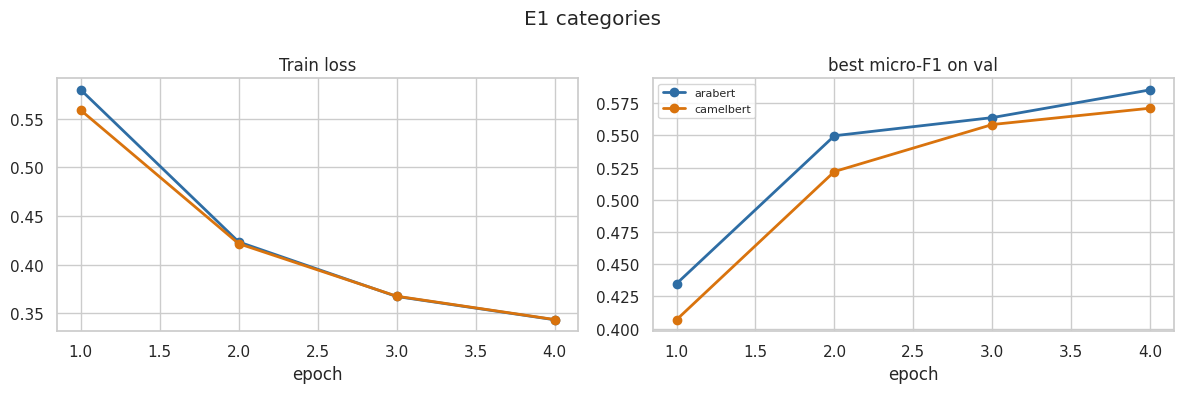

Best backbone for categories: arabert


In [8]:
category_first_runs = {"arabert": arabert_category, "camelbert": camelbert_category}
plot_model_comparison(pd.DataFrame(list(category_first_runs.values())), "micro_f1", title="E1 categories on val")
plot_training_curves({name: run["history"] for name, run in category_first_runs.items()}, "E1 categories", "best micro-F1 on val")

category_backbone = max(category_first_runs, key=lambda name: category_first_runs[name]["micro_f1"])
print("Best backbone for categories:", category_backbone)

### Polarity: `sentence [SEP] category name`

The model reads the Arabic name of the category like any other text, so each aspect of a sentence gets its own input.

In [9]:
def pair_rows(pair_table, backbone):
    """A pair with no single polarity gets the label -1, which is never used for training."""
    texts = pair_table.text.map(PREPARE_TEXT[backbone])
    category_names = [aspect_name(category, "arabic") for category in pair_table.category]
    labels = pair_table.polarity.map(polarity_ids).fillna(-1).astype(int).tolist()
    return tokenized_rows(tokenizers[backbone], texts, category_names, labels, MAX_LENGTH)


def polarity_logits(model, loader):
    return collect_outputs(loader, lambda batch: model(**token_inputs(batch)).logits)


def top_polarity(outputs):
    return np.array(POLARITIES, dtype=object)[outputs.argmax(dim=1).numpy()]


def run_e1_polarity(backbone, seed=SEED, retrain=False):
    val_loader = make_loader(pair_rows(val_units, backbone), backbone)

    def train_model():
        set_seed(seed)
        model = new_model(backbone, len(POLARITIES))
        train_loader = make_loader(pair_rows(train_units, backbone), backbone, shuffle=True)
        optimizer, scheduler = make_optimizer(model, len(train_loader))
        history = fit(
            model, train_loader,
            lambda model, batch: polarity_loss(model(**token_inputs(batch)).logits, batch["labels"]),
            lambda model: polarity_scores(val_units, top_polarity(polarity_logits(model, val_loader)))["macro_f1"],
            optimizer, scheduler, EPOCHS, PATIENCE, mixed_precision=True,
        )
        return {"state": compact_state(model), "predicted": top_polarity(polarity_logits(model, val_loader)), "history": history}

    run = cached_run(f"e1_polarity_{backbone}_seed{seed}", train_model, retrain)
    run.pop("state")
    result = polarity_scores(val_units, run["predicted"])
    fit_time = run["history"][-1]["seconds"]
    log_results([result_row("polarity", f"E1 fine-tuned {backbone}", "raw", "pair, lr=2e-5, weighted", fit_time_s=fit_time, seed=seed, **result)])
    print(f"{backbone}, seed {seed}: macro-F1 {result['macro_f1']:.4f}, accuracy {result['accuracy']:.4f}, {fit_time:.0f}s")
    return {"name": backbone, "seed": seed, "fit_time_s": fit_time, **run, **result}

In [10]:
arabert_polarity = run_e1_polarity("arabert")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1/4:   0%|          | 0/252 [00:00<?, ?it/s]

predicting:   0%|          | 0/30 [00:00<?, ?it/s]

epoch 1: loss 0.8635, val 0.6130, 46s


...

epoch 4/4:   0%|          | 0/252 [00:00<?, ?it/s]

predicting:   0%|          | 0/30 [00:00<?, ?it/s]

epoch 4: loss 0.3455, val 0.7177, 184s


predicting:   0%|          | 0/30 [00:00<?, ?it/s]

e1_polarity_arabert_seed42: saved
arabert, seed 42: macro-F1 0.7177, accuracy 0.8480, 184s


In [11]:
camelbert_polarity = run_e1_polarity("camelbert")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-msa
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSIN

epoch 1/4:   0%|          | 0/252 [00:00<?, ?it/s]

predicting:   0%|          | 0/30 [00:00<?, ?it/s]

epoch 1: loss 0.7568, val 0.6869, 45s


...

epoch 4/4:   0%|          | 0/252 [00:00<?, ?it/s]

predicting:   0%|          | 0/30 [00:00<?, ?it/s]

epoch 4: loss 0.2815, val 0.7546, 178s


predicting:   0%|          | 0/30 [00:00<?, ?it/s]

e1_polarity_camelbert_seed42: saved
camelbert, seed 42: macro-F1 0.7546, accuracy 0.8730, 178s


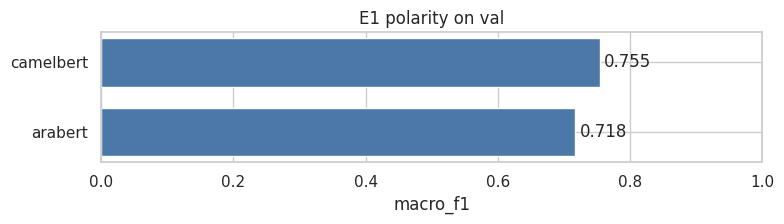

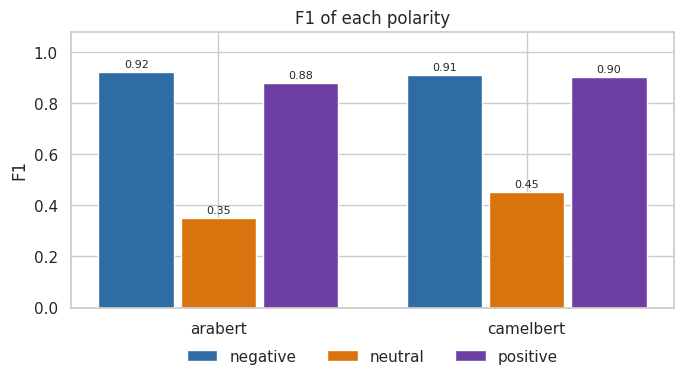

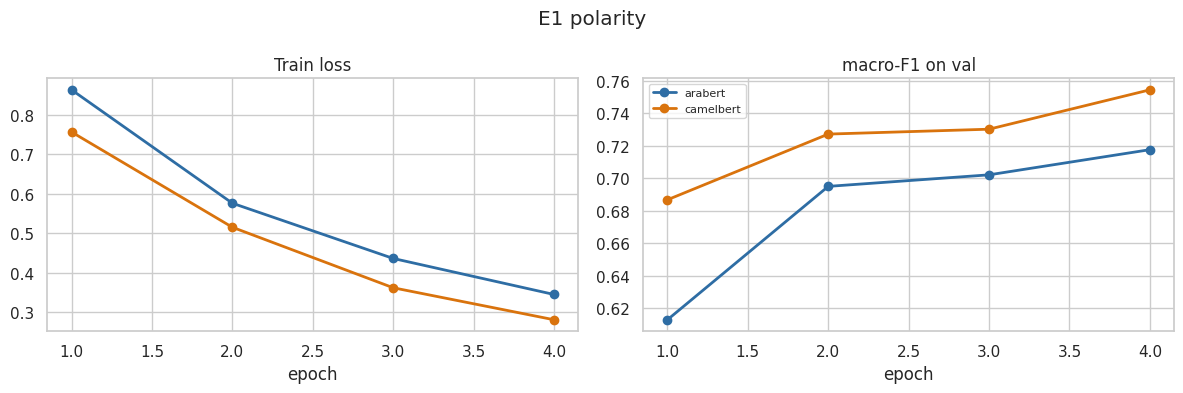

Best backbone for polarity: camelbert


In [12]:
polarity_first_runs = {"arabert": arabert_polarity, "camelbert": camelbert_polarity}
plot_model_comparison(pd.DataFrame(list(polarity_first_runs.values())), "macro_f1", title="E1 polarity on val")
plot_polarity_f1({name: polarity_f1_by_class(val_units, run["predicted"]) for name, run in polarity_first_runs.items()})
plot_training_curves({name: run["history"] for name, run in polarity_first_runs.items()}, "E1 polarity", "macro-F1 on val")

polarity_backbone = max(polarity_first_runs, key=lambda name: polarity_first_runs[name]["macro_f1"])
print("Best backbone for polarity:", polarity_backbone)

**Conclusions (Q8)**

_To fill in after the run: AraBERT against CAMeLBERT on each task, which one to keep, and why._

## 2. Seeds of the winners

In [13]:
category_seed_43 = run_e1_category(category_backbone, seed=43)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1/4:   0%|          | 0/135 [00:00<?, ?it/s]

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 1: loss 0.5764, val 0.4160, 24s


...

epoch 4/4:   0%|          | 0/135 [00:00<?, ?it/s]

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 4: loss 0.3479, val 0.5709, 93s


predicting:   0%|          | 0/16 [00:00<?, ?it/s]

e1_category_arabert_seed43: saved
arabert, seed 43: micro-F1 0.5709, macro-F1 0.2766, 93s


In [14]:
category_seed_44 = run_e1_category(category_backbone, seed=44)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1/4:   0%|          | 0/135 [00:00<?, ?it/s]

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 1: loss 0.5868, val 0.4248, 23s


...

epoch 4/4:   0%|          | 0/135 [00:00<?, ?it/s]

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 4: loss 0.3433, val 0.5818, 94s


predicting:   0%|          | 0/16 [00:00<?, ?it/s]

e1_category_arabert_seed44: saved
arabert, seed 44: micro-F1 0.5818, macro-F1 0.3073, 94s


In [15]:
polarity_seed_43 = run_e1_polarity(polarity_backbone, seed=43)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-msa
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSIN

epoch 1/4:   0%|          | 0/252 [00:00<?, ?it/s]

predicting:   0%|          | 0/30 [00:00<?, ?it/s]

epoch 1: loss 0.7928, val 0.6897, 45s


...

epoch 4/4:   0%|          | 0/252 [00:00<?, ?it/s]

predicting:   0%|          | 0/30 [00:00<?, ?it/s]

epoch 4: loss 0.2837, val 0.7574, 178s


predicting:   0%|          | 0/30 [00:00<?, ?it/s]

e1_polarity_camelbert_seed43: saved
camelbert, seed 43: macro-F1 0.7574, accuracy 0.8762, 178s


In [16]:
polarity_seed_44 = run_e1_polarity(polarity_backbone, seed=44)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-msa
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSIN

epoch 1/4:   0%|          | 0/252 [00:00<?, ?it/s]

predicting:   0%|          | 0/30 [00:00<?, ?it/s]

epoch 1: loss 0.7818, val 0.6399, 44s


...

epoch 4/4:   0%|          | 0/252 [00:00<?, ?it/s]

predicting:   0%|          | 0/30 [00:00<?, ?it/s]

epoch 4: loss 0.2712, val 0.7528, 177s


predicting:   0%|          | 0/30 [00:00<?, ?it/s]

e1_polarity_camelbert_seed44: saved
camelbert, seed 44: macro-F1 0.7528, accuracy 0.8610, 177s


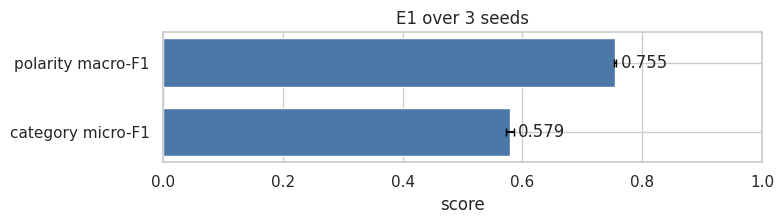

In [17]:
e1_category_runs = [category_first_runs[category_backbone], category_seed_43, category_seed_44]
e1_polarity_runs = [polarity_first_runs[polarity_backbone], polarity_seed_43, polarity_seed_44]

category_values = [run["micro_f1"] for run in e1_category_runs]
polarity_values = [run["macro_f1"] for run in e1_polarity_runs]
plot_model_comparison(pd.DataFrame([
    {"name": "category micro-F1", "score": np.mean(category_values), "std": np.std(category_values)},
    {"name": "polarity macro-F1", "score": np.mean(polarity_values), "std": np.std(polarity_values)},
]), "score", title="E1 over 3 seeds", error="std")

Global or per-category threshold, tuned on half of the val reviews and scored on the other half:

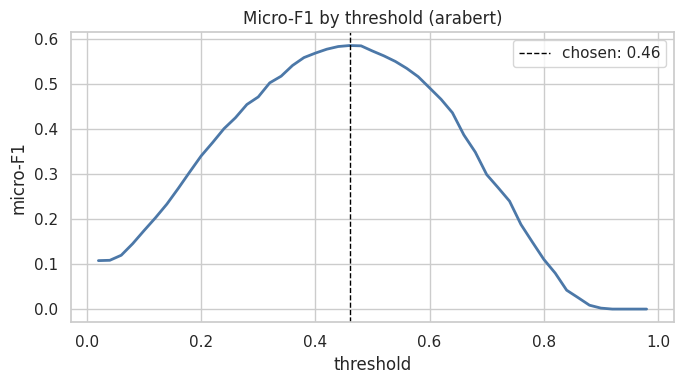

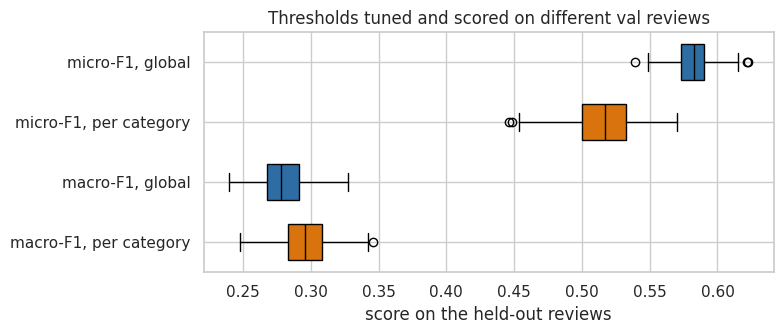

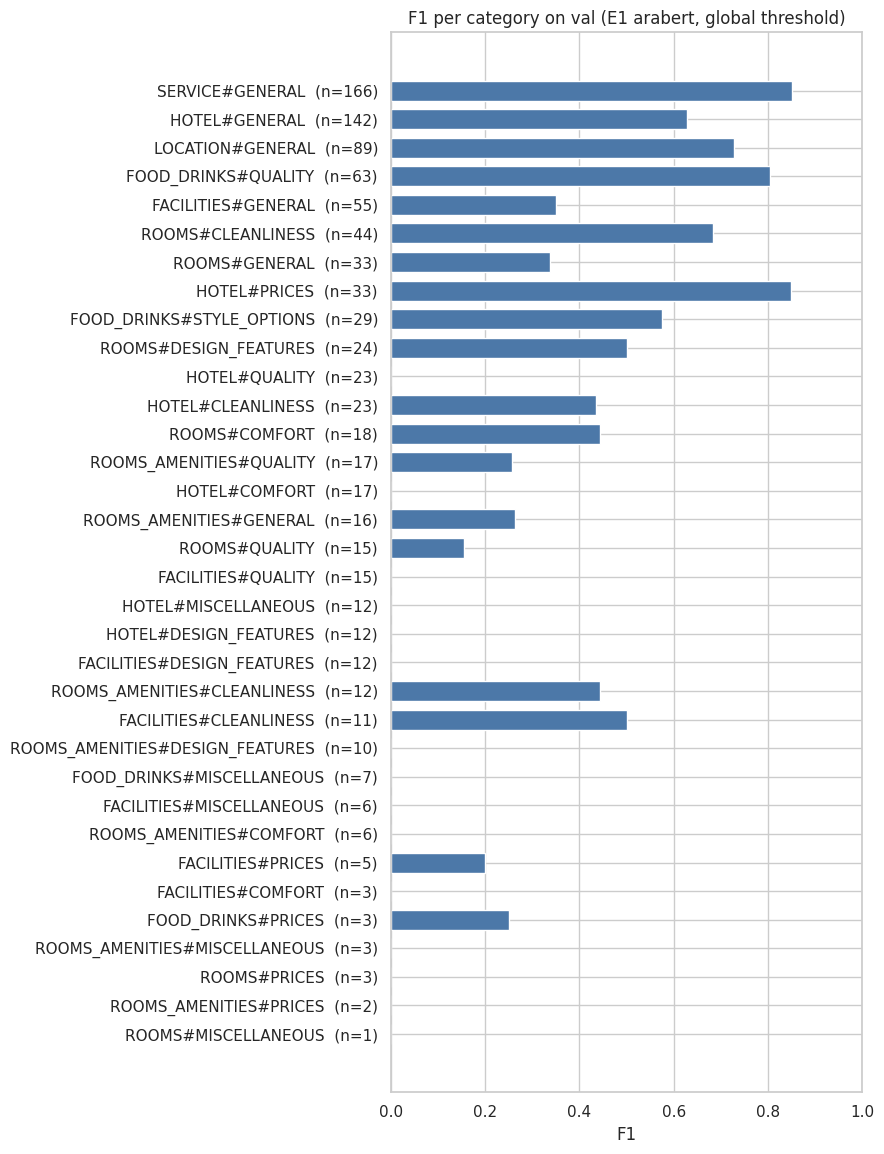

global threshold: 8 categories are never predicted


In [18]:
val_scores = e1_category_runs[0]["scores"]
global_threshold, f1_curve = best_global_threshold(val_scores, val_labels)
plot_f1_by_threshold(THRESHOLD_GRID, f1_curve, global_threshold, title=f"Micro-F1 by threshold ({category_backbone})")

holdout = compare_threshold_policies(val_scores, val_labels, val.review_id, seed=SEED)
plot_threshold_policies(holdout)

use_per_category = holdout.micro_f1_per_category.mean() > holdout.micro_f1_global.mean()
threshold_policy = "per_category" if use_per_category else "global"
chosen_thresholds = best_category_thresholds(val_scores, val_labels, global_threshold) if use_per_category else global_threshold

val_predictions = predict_labels(val_scores, chosen_thresholds)
report = category_report(val_labels, val_predictions, classes)
plot_category_f1(report, title=f"F1 per category on val (E1 {category_backbone}, {threshold_policy} threshold)")
print(f"{threshold_policy} threshold: {(report.predicted == 0).sum()} categories are never predicted")

## 3. E2: one encoder, two heads

The loss is `category loss + λ × polarity loss`. The category head reads [CLS]. The polarity head reads every token through an attention conditioned on the aspect, so one sentence in a batch trains all its aspects.

Category detection is the main task, so early stopping watches its micro-F1. Three values of λ show the effect of the auxiliary task (Q9).

In [19]:
class MultiTaskBert(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.bert = AutoModel.from_pretrained(BERT_NAMES[backbone])
        hidden_size = self.bert.config.hidden_size
        self.dropout = nn.Dropout(0.1)
        self.category_head = nn.Linear(hidden_size, len(classes))
        self.aspect_embedding = nn.Embedding(len(classes), ASPECT_SIZE)
        self.word_score = nn.Linear(hidden_size + ASPECT_SIZE, 1)
        self.polarity_head = nn.Linear(hidden_size + ASPECT_SIZE, len(POLARITIES))

    def forward(self, **tokens):
        return self.bert(**tokens).last_hidden_state

    def category_outputs(self, states):
        return self.category_head(self.dropout(states[:, 0]))

    def polarity_outputs(self, states, attention_mask, sentence_rows, aspects):
        """sentence_rows gives, for each pair, the row of its sentence in the batch."""
        aspect_vectors = self.aspect_embedding(aspects)
        pair_states = states[sentence_rows]
        queries = aspect_vectors.unsqueeze(1).expand(-1, pair_states.size(1), -1)
        word_scores = self.word_score(torch.cat([pair_states, queries], dim=2)).squeeze(2)
        weights = word_scores.masked_fill(attention_mask[sentence_rows] == 0, -1e4).softmax(dim=1)
        summary = (weights.unsqueeze(2) * pair_states).sum(dim=1)
        return self.polarity_head(self.dropout(torch.cat([summary, aspect_vectors], dim=1)))

In [20]:
class MultiTaskCollator:
    """Each row has `pairs`, a list of (aspect id, polarity id) for its sentence."""

    def __init__(self, backbone):
        self.pad_tokens = DataCollatorWithPadding(tokenizers[backbone])

    def __call__(self, rows):
        batch = self.pad_tokens([{name: value for name, value in row.items() if name != "pairs"} for row in rows])
        pairs_in_batch = [(row_index, *pair) for row_index, row in enumerate(rows) for pair in row["pairs"]]
        batch["sentence_rows"], batch["aspects"], batch["polarities"] = torch.tensor(pairs_in_batch, dtype=torch.long).reshape(-1, 3).T
        return batch


def multitask_loader(rows, backbone, shuffle=False):
    return DataLoader(rows, batch_size=BATCH_SIZE, shuffle=shuffle, collate_fn=MultiTaskCollator(backbone))


pairs_by_sentence = {sentence_id: [] for sentence_id in train.sentence_id}
for row in train_units.itertuples():
    pairs_by_sentence[row.sentence_id].append((category_ids[row.category], polarity_ids[row.polarity]))


def multitask_train_rows(backbone):
    rows = sentence_rows(train, backbone, train_labels)
    return [row | {"pairs": pairs_by_sentence[sentence_id]} for row, sentence_id in zip(rows, train.sentence_id)]


def multitask_pair_rows(pair_table, backbone):
    rows = tokenized_rows(tokenizers[backbone], pair_table.text.map(PREPARE_TEXT[backbone]), max_length=MAX_LENGTH)
    return [row | {"pairs": [(category_ids[category], 0)]} for row, category in zip(rows, pair_table.category)]


def multitask_probabilities(model, loader):
    return collect_outputs(loader, lambda batch: model.category_outputs(model(**token_inputs(batch)))).sigmoid().numpy()


def multitask_polarity_logits(model, loader):
    return collect_outputs(loader, lambda batch: model.polarity_outputs(
        model(**token_inputs(batch)), batch["attention_mask"], batch["sentence_rows"], batch["aspects"],
    ))


def multitask_loss(model, batch, polarity_weight):
    states = model(**token_inputs(batch))
    loss = category_loss(model.category_outputs(states), batch["labels"])
    if len(batch["aspects"]) > 0:
        outputs = model.polarity_outputs(states, batch["attention_mask"], batch["sentence_rows"], batch["aspects"])
        loss = loss + polarity_weight * polarity_loss(outputs, batch["polarities"])
    return loss

In [21]:
def run_e2(polarity_weight, seed=SEED, retrain=False):
    backbone = category_backbone
    val_loader = make_loader(sentence_rows(val, backbone, val_labels), backbone)
    pair_loader = multitask_loader(multitask_pair_rows(val_units, backbone), backbone)

    def train_model():
        set_seed(seed)
        model = MultiTaskBert(backbone).to(DEVICE)
        train_loader = multitask_loader(multitask_train_rows(backbone), backbone, shuffle=True)
        optimizer, scheduler = make_optimizer(model, len(train_loader))
        history = fit(
            model, train_loader,
            lambda model, batch: multitask_loss(model, batch, polarity_weight),
            lambda model: category_result(multitask_probabilities(model, val_loader))["micro_f1"],
            optimizer, scheduler, EPOCHS, PATIENCE, mixed_precision=True,
        )
        return {"state": compact_state(model), "scores": multitask_probabilities(model, val_loader),
                "predicted": top_polarity(multitask_polarity_logits(model, pair_loader)), "history": history}

    run = cached_run(f"e2_{backbone}_lambda{polarity_weight:g}_seed{seed}", train_model, retrain)
    run.pop("state")
    categories = category_result(run["scores"])
    polarity = polarity_scores(val_units, run["predicted"])
    fit_time = run["history"][-1]["seconds"]
    params = f"lambda={polarity_weight:g}"
    log_results([
        result_row("category", f"E2 multi-task {backbone}", "raw", params, "global", fit_time, seed=seed, **categories),
        result_row("polarity", f"E2 multi-task {backbone}", "raw", params, fit_time_s=fit_time, seed=seed, **polarity),
    ])
    print(f"{params}, seed {seed}: micro-F1 {categories['micro_f1']:.4f}, polarity macro-F1 {polarity['macro_f1']:.4f}, {fit_time:.0f}s")
    return {"name": params, "polarity_weight": polarity_weight, "seed": seed, "fit_time_s": fit_time, "scores": run["scores"], "predicted": run["predicted"],
            "history": run["history"], "micro_f1": categories["micro_f1"], "polarity_macro_f1": polarity["macro_f1"]}

In [22]:
e2_lambda_03 = run_e2(0.3)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1/4:   0%|          | 0/135 [00:00<?, ?it/s]

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 1: loss 0.7915, val 0.4362, 24s


...

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 4: loss 0.4367, val 0.5796, 95s


predicting:   0%|          | 0/16 [00:00<?, ?it/s]

predicting:   0%|          | 0/30 [00:00<?, ?it/s]

e2_arabert_lambda0.3_seed42: saved
lambda=0.3, seed 42: micro-F1 0.5796, polarity macro-F1 0.6968, 95s


In [23]:
e2_lambda_1 = run_e2(1.0)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1/4:   0%|          | 0/135 [00:00<?, ?it/s]

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 1: loss 1.3940, val 0.3664, 24s


...

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 4: loss 0.7633, val 0.4937, 94s


predicting:   0%|          | 0/16 [00:00<?, ?it/s]

predicting:   0%|          | 0/30 [00:00<?, ?it/s]

e2_arabert_lambda1_seed42: saved
lambda=1, seed 42: micro-F1 0.4937, polarity macro-F1 0.6830, 94s


In [24]:
e2_lambda_3 = run_e2(3.0)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1/4:   0%|          | 0/135 [00:00<?, ?it/s]

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 1: loss 3.0444, val 0.3174, 24s


...

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 4: loss 1.5196, val 0.3769, 95s


predicting:   0%|          | 0/16 [00:00<?, ?it/s]

predicting:   0%|          | 0/30 [00:00<?, ?it/s]

e2_arabert_lambda3_seed42: saved
lambda=3, seed 42: micro-F1 0.3769, polarity macro-F1 0.6797, 95s


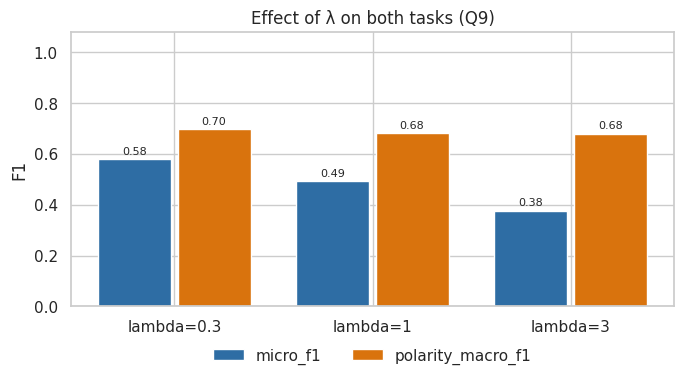

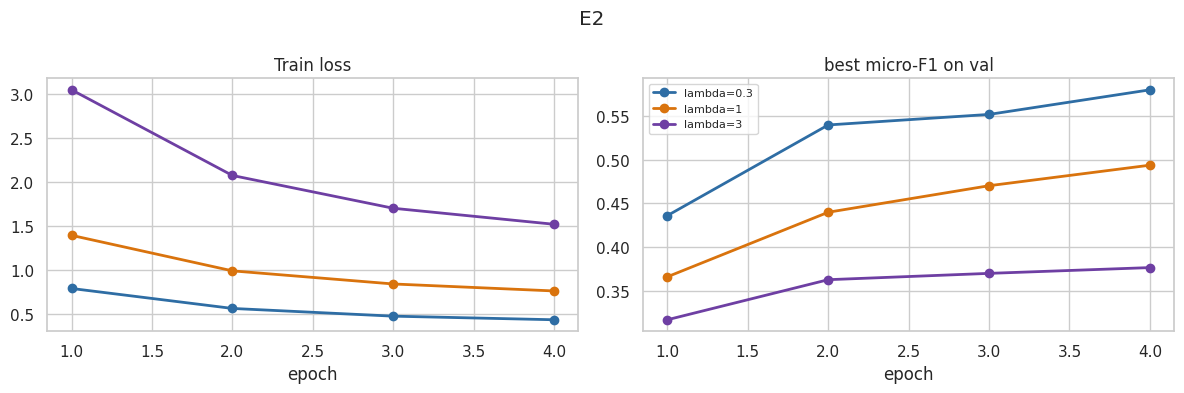

Best λ: 0.3


In [25]:
e2_lambda_runs = [e2_lambda_03, e2_lambda_1, e2_lambda_3]
plot_grouped_bars(pd.DataFrame(e2_lambda_runs).set_index("name")[["micro_f1", "polarity_macro_f1"]], "F1", "Effect of λ on both tasks (Q9)")
plot_training_curves({run["name"]: run["history"] for run in e2_lambda_runs}, "E2", "best micro-F1 on val")

best_e2 = max(e2_lambda_runs, key=lambda run: run["micro_f1"])
best_lambda = best_e2["polarity_weight"]
print("Best λ:", best_lambda)

In [26]:
e2_seed_43 = run_e2(best_lambda, seed=43)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1/4:   0%|          | 0/135 [00:00<?, ?it/s]

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 1: loss 0.7658, val 0.4396, 24s


...

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 4: loss 0.4360, val 0.5735, 95s


predicting:   0%|          | 0/16 [00:00<?, ?it/s]

predicting:   0%|          | 0/30 [00:00<?, ?it/s]

e2_arabert_lambda0.3_seed43: saved
lambda=0.3, seed 43: micro-F1 0.5735, polarity macro-F1 0.6911, 95s


In [27]:
e2_seed_44 = run_e2(best_lambda, seed=44)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1/4:   0%|          | 0/135 [00:00<?, ?it/s]

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 1: loss 0.7981, val 0.4575, 24s


...

predicting:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 4: loss 0.4331, val 0.5582, 95s


predicting:   0%|          | 0/16 [00:00<?, ?it/s]

predicting:   0%|          | 0/30 [00:00<?, ?it/s]

e2_arabert_lambda0.3_seed44: saved
lambda=0.3, seed 44: micro-F1 0.5582, polarity macro-F1 0.6943, 95s


## 4. E1 pipeline against E2

Two models trained apart, against one model trained on both tasks.

In [28]:
def load_e1(task, backbone, seed):
    model = new_model(backbone, len(classes) if task == "category" else len(POLARITIES))
    model.load_state_dict(cached_run(f"e1_{task}_{backbone}_seed{seed}", None)["state"])
    return model.eval()


def load_e2(seed):
    model = MultiTaskBert(category_backbone).to(DEVICE)
    model.load_state_dict(cached_run(f"e2_{category_backbone}_lambda{best_lambda:g}_seed{seed}", None)["state"])
    return model.eval()


def e1_pair_logits(model, pair_table):
    return polarity_logits(model, make_loader(pair_rows(pair_table.assign(polarity=None), polarity_backbone), polarity_backbone))


def e2_pair_logits(model, pair_table):
    return multitask_polarity_logits(model, multitask_loader(multitask_pair_rows(pair_table, category_backbone), category_backbone))

In [29]:
e1_pairs = pairs_from_matrix(val, val_predictions, classes)
e1_pair_polarities = top_polarity(cached_run("e1_pipeline_val", lambda: e1_pair_logits(load_e1("polarity", polarity_backbone, SEED), e1_pairs)))
e1_outcomes = pipeline_outcomes(val_pairs, e1_pairs.assign(polarity=e1_pair_polarities))
e1_pipeline = pipeline_scores(e1_outcomes)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-msa
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSIN

e1_polarity_camelbert_seed42: loaded from disk


predicting:   0%|          | 0/30 [00:00<?, ?it/s]

e1_pipeline_val: saved


In [30]:
e2_threshold, _ = best_global_threshold(best_e2["scores"], val_labels)
e2_pairs = pairs_from_matrix(val, predict_labels(best_e2["scores"], e2_threshold), classes)
e2_pair_polarities = top_polarity(cached_run("e2_pipeline_val", lambda: e2_pair_logits(load_e2(SEED), e2_pairs)))
e2_outcomes = pipeline_outcomes(val_pairs, e2_pairs.assign(polarity=e2_pair_polarities))
e2_pipeline = pipeline_scores(e2_outcomes)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


e2_arabert_lambda0.3_seed42: loaded from disk


predicting:   0%|          | 0/28 [00:00<?, ?it/s]

e2_pipeline_val: saved


/content/AR-aspect-sentiment/src/tracking.py:55: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([pd.read_csv(path), table], ignore_index=True)


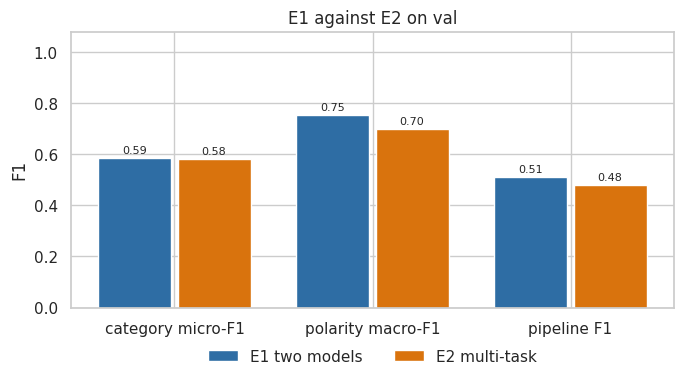

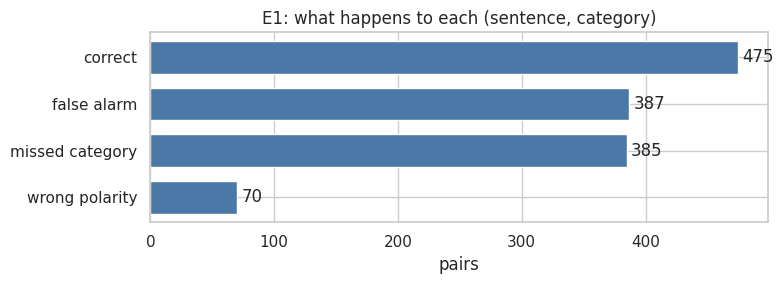

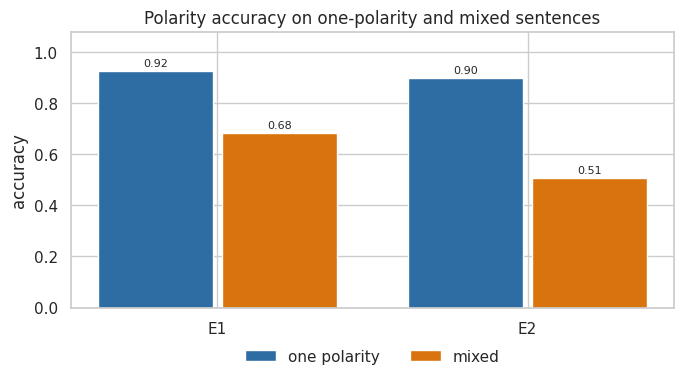

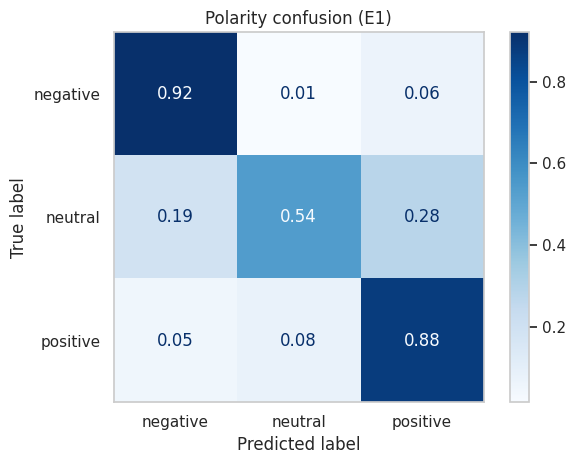

In [31]:
results = log_results([
    result_row("pipeline", "E1 two models", "raw", f"{category_backbone} + {polarity_backbone}", threshold_policy, micro_f1=e1_pipeline["pipeline_f1"]),
    result_row("pipeline", "E2 multi-task", "raw", f"lambda={best_lambda:g}", "global", micro_f1=e2_pipeline["pipeline_f1"]),
])

plot_grouped_bars(pd.DataFrame({
    "E1 two models": {"category micro-F1": e1_category_runs[0]["micro_f1"], "polarity macro-F1": e1_polarity_runs[0]["macro_f1"], "pipeline F1": e1_pipeline["pipeline_f1"]},
    "E2 multi-task": {"category micro-F1": best_e2["micro_f1"], "polarity macro-F1": best_e2["polarity_macro_f1"], "pipeline F1": e2_pipeline["pipeline_f1"]},
}), "F1", "E1 against E2 on val")
plot_pipeline_outcomes(e1_outcomes, title="E1: what happens to each (sentence, category)")
plot_mixed_accuracy({
    "E1": accuracy_by_mixed_sentence(val_units, e1_polarity_runs[0]["predicted"]),
    "E2": accuracy_by_mixed_sentence(val_units, best_e2["predicted"]),
})
plot_polarity_confusion(val_units.polarity[clear_units], e1_polarity_runs[0]["predicted"][clear_units], title="Polarity confusion (E1)")

**Conclusions (Q9)**

_To fill in after the run: does the joint training help the main task, the effect of λ, and why an auxiliary task can help or hurt._

## 5. Gain and cost against frozen BERT (Q8)

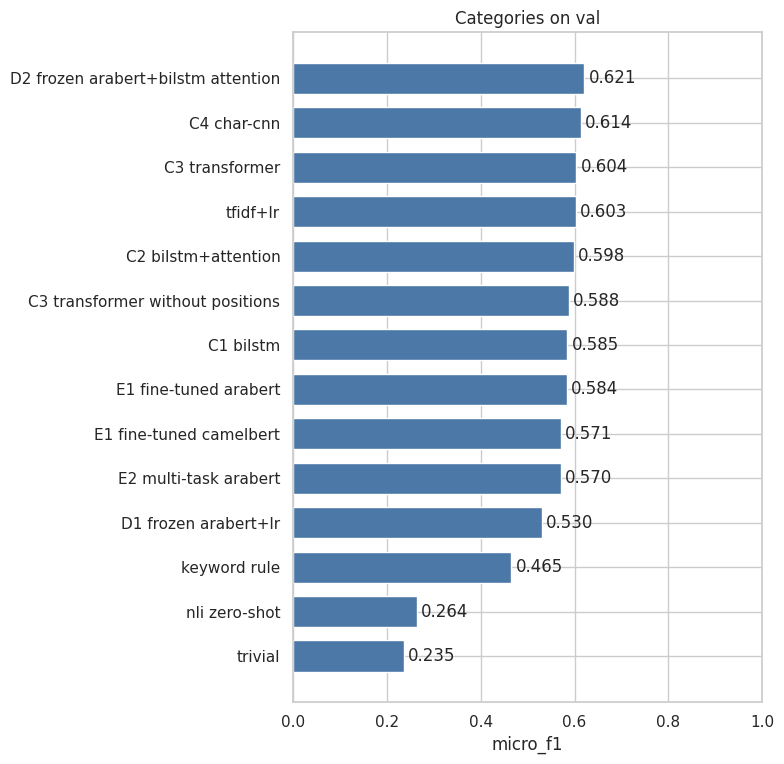

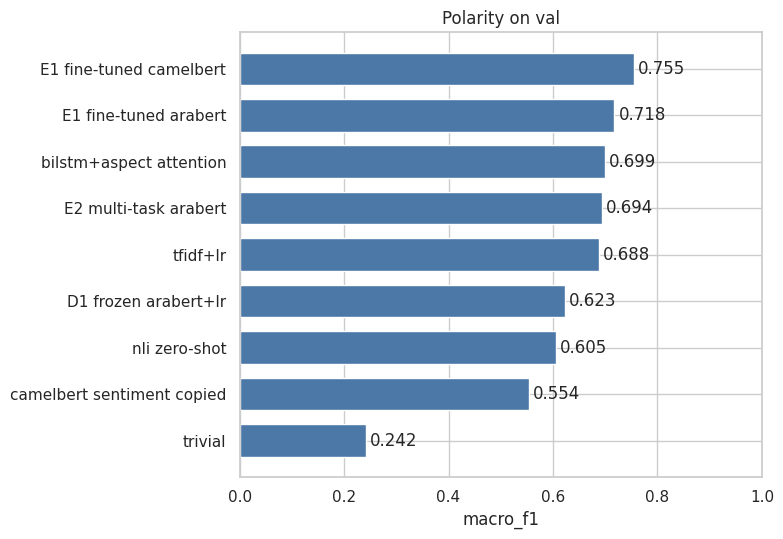

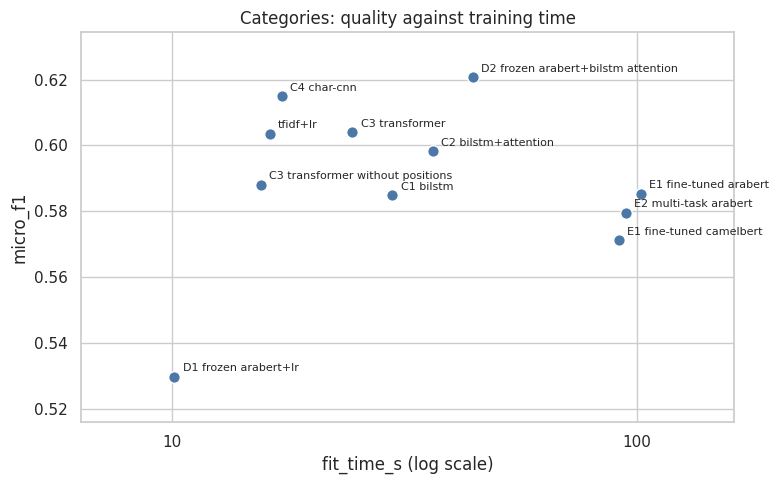

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


e1_category_arabert_seed42: loaded from disk
Fine-tuned BERT trains 135.2 million parameters, D1 trains 0.026 million


In [32]:
plot_model_comparison(best_of_each_model(results, "category", "micro_f1"), "micro_f1", title="Categories on val")
plot_model_comparison(best_of_each_model(results, "polarity", "macro_f1"), "macro_f1", title="Polarity on val")

timed_runs = results[(results.task == "category") & (results.threshold_policy != "per_category")].dropna(subset=["fit_time_s"])
time_table = timed_runs.groupby("model", as_index=False).agg(fit_time_s=("fit_time_s", "mean"), micro_f1=("micro_f1", "max")).rename(columns={"model": "name"})
plot_quality_against_cost(time_table, "fit_time_s", "micro_f1", title="Categories: quality against training time")

trained_parameters = sum(parameter.numel() for parameter in load_e1("category", category_backbone, SEED).parameters())
print(f"Fine-tuned BERT trains {trained_parameters / 1e6:.1f} million parameters, D1 trains {769 * len(classes) / 1e6:.3f} million")

**Conclusions (Q8)**

_To fill in after the run: gain of fine-tuning over frozen BERT, and its cost in time and in trained parameters._

## 6. Save the val scores

In [33]:
thresholds_to_save = np.broadcast_to(chosen_thresholds, len(classes)).tolist()
sentence_ids = {"sentence_id": val.sentence_id.to_numpy()}

save_scores("fine_tuned_category", "val", val_scores, sentence_ids, classes,
            meta={"backbone": category_backbone, "polarity_backbone": polarity_backbone, "threshold_policy": threshold_policy, "thresholds": thresholds_to_save})
save_scores("multitask_category", "val", best_e2["scores"], sentence_ids, classes,
            meta={"backbone": category_backbone, "lambda": best_lambda, "thresholds": [e2_threshold] * len(classes)})

## 7. Test predictions for Part F


Run this section only when the choices above are final. It writes the predictions on the test set for `06_final_test` and prints no score, so nothing here can influence a choice.

In [34]:
SEEDS = [42, 43, 44]
test_opinions, test = load_test()
test_units = pair_units(pairs(test_opinions, test))
pair_ids = {"sentence_id": test_units.sentence_id.to_numpy(), "category": test_units.category.to_numpy()}
sentence_ids = {"sentence_id": test.sentence_id.to_numpy()}
category_test_loader = make_loader(sentence_rows(test, category_backbone), category_backbone)


def saved_pair_ids(pair_table):
    return {"sentence_id": pair_table.sentence_id.to_numpy(), "category": pair_table.category.to_numpy()}

In [35]:
e1_test_scores = cached_run("e1_category_test", lambda: [category_probabilities(load_e1("category", category_backbone, seed), category_test_loader) for seed in SEEDS])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


e1_category_arabert_seed42: loaded from disk


predicting:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


e1_category_arabert_seed44: loaded from disk


predicting:   0%|          | 0/39 [00:00<?, ?it/s]

e1_category_test: saved


In [36]:
e1_test_polarities = cached_run("e1_polarity_test", lambda: [e1_pair_logits(load_e1("polarity", polarity_backbone, seed), test_units).softmax(dim=1).numpy() for seed in SEEDS])
save_scores("fine_tuned_polarity", "test", e1_test_polarities, pair_ids, POLARITIES)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-msa
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSIN

e1_polarity_camelbert_seed42: loaded from disk


predicting:   0%|          | 0/71 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-msa
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSIN

e1_polarity_camelbert_seed44: loaded from disk


predicting:   0%|          | 0/71 [00:00<?, ?it/s]

e1_polarity_test: saved


In [37]:
e1_test_pairs = pairs_from_matrix(test, predict_labels(e1_test_scores[0], chosen_thresholds), classes)
e1_test_pipeline = cached_run("e1_pipeline_test", lambda: e1_pair_logits(load_e1("polarity", polarity_backbone, SEED), e1_test_pairs).softmax(dim=1).numpy())
save_scores("fine_tuned_pipeline", "test", [e1_test_pipeline], saved_pair_ids(e1_test_pairs), POLARITIES)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-msa
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSIN

e1_polarity_camelbert_seed42: loaded from disk


predicting:   0%|          | 0/72 [00:00<?, ?it/s]

e1_pipeline_test: saved


In [38]:
e2_test_scores = cached_run("e2_category_test", lambda: [multitask_probabilities(load_e2(seed), category_test_loader) for seed in SEEDS])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


e2_arabert_lambda0.3_seed42: loaded from disk


predicting:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


e2_arabert_lambda0.3_seed44: loaded from disk


predicting:   0%|          | 0/39 [00:00<?, ?it/s]

e2_category_test: saved


In [39]:
e2_test_polarities = cached_run("e2_polarity_test", lambda: [e2_pair_logits(load_e2(seed), test_units).softmax(dim=1).numpy() for seed in SEEDS])
save_scores("multitask_polarity", "test", e2_test_polarities, pair_ids, POLARITIES)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


e2_arabert_lambda0.3_seed42: loaded from disk


predicting:   0%|          | 0/71 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


e2_arabert_lambda0.3_seed44: loaded from disk


predicting:   0%|          | 0/71 [00:00<?, ?it/s]

e2_polarity_test: saved


In [40]:
e2_test_pairs = pairs_from_matrix(test, predict_labels(e2_test_scores[0], e2_threshold), classes)
e2_test_pipeline = cached_run("e2_pipeline_test", lambda: e2_pair_logits(load_e2(SEED), e2_test_pairs).softmax(dim=1).numpy())
save_scores("multitask_pipeline", "test", [e2_test_pipeline], saved_pair_ids(e2_test_pairs), POLARITIES)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


e2_arabert_lambda0.3_seed42: loaded from disk


predicting:   0%|          | 0/68 [00:00<?, ?it/s]

e2_pipeline_test: saved


CPU latency of one sentence:

In [41]:
def size_mb(model):
    return sum(parameter.numel() for parameter in model.parameters()) * 4 / 1e6


latency_texts = test.text.head(50).tolist()
e1_model = load_e1("category", category_backbone, SEED).cpu()
e2_model = load_e2(SEED).cpu()


def tokens_of(text):
    return tokenizers[category_backbone](PREPARE_TEXT[category_backbone](text), truncation=True, max_length=MAX_LENGTH, return_tensors="pt")


def predict_with_e1(text):
    with torch.inference_mode():
        return e1_model(**tokens_of(text))


def predict_with_e2(text):
    with torch.inference_mode():
        return e2_model.category_outputs(e2_model(**tokens_of(text)))


save_scores("fine_tuned_category", "test", e1_test_scores, sentence_ids, classes, meta={
    "thresholds": thresholds_to_save, "train_s": e1_category_runs[0]["fit_time_s"],
    "latency_ms": latency_ms(predict_with_e1, latency_texts), "size_mb": size_mb(e1_model),
    "backbone": category_backbone, "polarity_backbone": polarity_backbone,
})
save_scores("multitask_category", "test", e2_test_scores, sentence_ids, classes, meta={
    "thresholds": [e2_threshold] * len(classes), "train_s": best_e2["fit_time_s"],
    "latency_ms": latency_ms(predict_with_e2, latency_texts), "size_mb": size_mb(e2_model),
})

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


e1_category_arabert_seed42: loaded from disk


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


e2_arabert_lambda0.3_seed42: loaded from disk
